# 03 — Score your own finder (worked example with DisPerSE)

The recipe for any finder:

1. run it on `mock_particles_s{seed}.npz`;
2. load its skeleton as a list of (M,3) polylines (or an (N,3) cloud of points along it);
3. `gtweb.score_finder(skeleton, spines, box, tol)` for completeness and purity,
   `gtweb.score_per_filament(...)` for which filaments it finds;
4. repeat on several seeds: a single mock is one realisation.

This notebook does it with [DisPerSE](https://github.com/thierry-sousbie/DisPerSE) on the mock from
notebook 01 (regenerated here if missing). If DisPerSE is not on your `PATH` the DisPerSE cells are
skipped and a toy skeleton is used, so the scoring cells still run.

It also shows one way to set a finder's free threshold without looking at the true filaments: match
its density maxima to the most massive true nodes, as in the paper.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

try:
    import gtweb
except ImportError:                       # running from a clone without `pip install -e .`
    sys.path.insert(0, str(Path.cwd().parent))
    import gtweb

plt.style.use(Path(gtweb.__file__).parent / "gtweb.mplstyle")
print("gtweb", gtweb.__version__)
import json, shutil, subprocess

OUT = Path("mock_quickstart")
if not (OUT / "ground_truth_spines.npz").exists():
    gtweb.generate_mock(OUT, box=50.0, ngrid=64, seed=1)
seed = json.loads((OUT / "metadata.json").read_text())["seed"]
gt = gtweb.load_ground_truth(OUT / "ground_truth_spines.npz")
box, spines = float(gt["box_size"]), gt["spines"]
nodes = gtweb.load_nodes(OUT / "nodes_catalogue.npz")
pos = np.asarray(gtweb.load_particles(OUT / f"mock_particles_s{seed}.npz")["positions"], float)
HAVE_DISPERSE = all(shutil.which(b) for b in ("delaunay_3D", "mse", "skelconv"))
print(f"{len(spines)} true filaments, {len(pos):,} particles; DisPerSE found: {HAVE_DISPERSE}")

gtweb 1.0.0
854 true filaments, 262,144 particles; DisPerSE found: True


## 1. Run DisPerSE

We tessellate a random eighth of the particles (DisPerSE's DTFE density) and extract the skeleton at a
few persistence thresholds `nsig`. The commands are the standard ones:

```
delaunay_3D sample.pos -periodic
mse sample.pos.NDnet -periodicity 111 -nsig <n> -upSkl -forceLoops
skelconv sample.pos.NDnet_s<n>.up.NDskl -breakdown -smooth 8 -to NDskl_ascii
```

In [2]:
RUN = OUT / "disperse"
RUN.mkdir(exist_ok=True)
NSIGS = [2, 3, 4, 5, 6, 7, 8]
skeletons, maxima = {}, {}
if HAVE_DISPERSE:
    rng = np.random.default_rng(0)
    sample = pos[rng.choice(len(pos), len(pos) // 8, replace=False)]
    gtweb.write_disperse_pos(sample, RUN / "sample.pos", box)
    run = lambda *a: subprocess.run(a, cwd=RUN, check=True, capture_output=True)
    run("delaunay_3D", "sample.pos", "-periodic")
    for n in NSIGS:
        run("mse", "sample.pos.NDnet", "-periodicity", "111", "-nsig", str(n), "-upSkl", "-forceLoops")
        run("skelconv", f"sample.pos.NDnet_s{n}.up.NDskl", "-breakdown", "-smooth", "8", "-to", "NDskl_ascii")
        f = RUN / f"sample.pos.NDnet_s{n}.up.NDskl.BRK.S008.a.NDskl"
        skeletons[n] = gtweb.read_disperse_skeleton(f)
        cp = gtweb.read_disperse_critical_points(f)
        maxima[n] = cp["positions"][cp["type"] == 3] % box
else:                                                    # toy stand-in: the truth, jittered and thinned
    rng = np.random.default_rng(0)
    for n in NSIGS:
        keep = rng.random(len(spines)) < 1.1 - 0.15 * n
        skeletons[n] = [np.asarray(s) + rng.normal(0, 0.5, np.asarray(s).shape) for s, k in zip(spines, keep) if k]
        maxima[n] = nodes["positions"][rng.random(len(nodes["positions"])) < 1.1 - 0.15 * n]
for n, sk in skeletons.items():
    print(f"nsig {n}: {len(sk)} skeleton pieces, {len(maxima[n])} maxima")

nsig 2: 2680 skeleton pieces, 775 maxima
nsig 3: 1943 skeleton pieces, 643 maxima
nsig 4: 1444 skeleton pieces, 486 maxima
nsig 5: 829 skeleton pieces, 299 maxima
nsig 6: 259 skeleton pieces, 88 maxima
nsig 7: 23 skeleton pieces, 4 maxima
nsig 8: 10 skeleton pieces, 1 maxima


## 2. Completeness and purity

Raising the threshold removes the less significant filaments: purity rises, completeness falls.

nsig  2  tol 1.0  completeness 0.728  purity 0.704
nsig  2  tol 2.0  completeness 0.874  purity 0.816
nsig  3  tol 1.0  completeness 0.692  purity 0.780
nsig  3  tol 2.0  completeness 0.841  purity 0.875
nsig  4  tol 1.0  completeness 0.654  purity 0.832
nsig  4  tol 2.0  completeness 0.808  purity 0.916
nsig  5  tol 1.0  completeness 0.572  purity 0.861
nsig  5  tol 2.0  completeness 0.738  purity 0.932
nsig  6  tol 1.0  completeness 0.382  purity 0.879
nsig  6  tol 2.0  completeness 0.521  purity 0.937
nsig  7  tol 1.0  completeness 0.128  purity 0.933
nsig  7  tol 2.0  completeness 0.175  purity 0.962
nsig  8  tol 1.0  completeness 0.095  purity 0.963
nsig  8  tol 2.0  completeness 0.134  purity 0.998


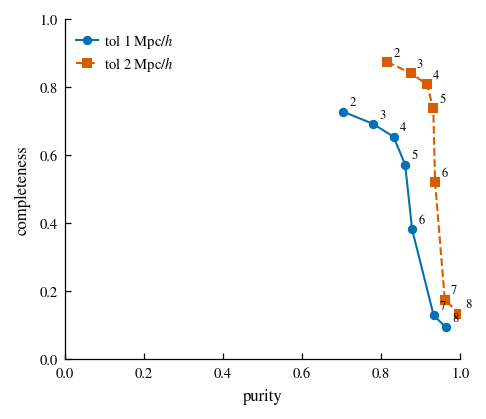

In [3]:
rows = []
for n, sk in skeletons.items():
    for tol in (1.0, 2.0):
        s = gtweb.score_finder(sk, spines, box, tol=tol)
        rows.append((n, tol, s["completeness"], s["purity"]))
for r in rows:
    print("nsig {:>2}  tol {:.1f}  completeness {:.3f}  purity {:.3f}".format(*r))

fig, ax = plt.subplots(figsize=(3.4, 3.0))
for tol, mk in ((1.0, "o-"), (2.0, "s--")):
    rr = [r for r in rows if r[1] == tol]
    ax.plot([r[3] for r in rr], [r[2] for r in rr], mk, label=f"tol {tol:g} Mpc/$h$")
    for r in rr:
        ax.annotate(f"{r[0]}", (r[3], r[2]), textcoords="offset points", xytext=(3, 3), fontsize=6)
ax.set(xlabel="purity", ylabel="completeness", xlim=(0, 1), ylim=(0, 1))
ax.legend()
plt.show()

## 3. Choosing the threshold without the true filaments

A fair comparison of finders needs each one at an operating point chosen without the answer. In the
paper the threshold is set on the **nodes**: take the most massive 10 per cent of the true nodes as
anchors; node purity is the fraction of the skeleton's density maxima within 1.5 Mpc/h of an anchor,
node completeness the fraction of anchors with a maximum within 1.5 Mpc/h; pick the threshold where
the two are equal. Only node positions and masses are used, which a real survey can approximate with
massive haloes or clusters. DisPerSE lists the maxima in the critical-point block of its
`.NDskl` file (type 3 in 3D), which `gtweb.read_disperse_critical_points` reads.

In [4]:
from scipy.spatial import cKDTree

peaks = np.asarray(nodes["peaks"])
anchors = nodes["positions"][peaks >= np.percentile(peaks, 90)]
ta = cKDTree(anchors, boxsize=box)


def node_scores(maxima, ap=1.5):
    pur = np.mean(ta.query(maxima)[0] < ap)
    comp = np.mean(cKDTree(maxima, boxsize=box).query(anchors)[0] < ap)
    return pur, comp


ns = np.array(list(skeletons))
pc = np.array([node_scores(maxima[n]) for n in ns])
ratio = pc[:, 0] / pc[:, 1]
for n, (p, c) in zip(ns, pc):
    print(f"nsig {n}: node purity {p:.3f}, node completeness {c:.3f}")
if ratio.min() < 1 < ratio.max():
    o = np.argsort(ratio)
    print(f"purity = completeness at nsig ~ {np.interp(1.0, ratio[o], ns[o]):.2f}")

nsig 2: node purity 0.076, node completeness 1.000
nsig 3: node purity 0.089, node completeness 1.000
nsig 4: node purity 0.095, node completeness 1.000
nsig 5: node purity 0.094, node completeness 0.837
nsig 6: node purity 0.125, node completeness 0.395
nsig 7: node purity 0.250, node completeness 0.047
nsig 8: node purity 1.000, node completeness 0.047
purity = completeness at nsig ~ 6.14


For this input the crossing sits at a high threshold, where the skeleton has already lost much of
the network. The maxima of a tessellation of a sparse particle sample are dominated by shot noise,
so node purity stays low until the threshold also removes real structure. This is the behaviour
the paper reports for an unsmoothed tessellation input: the density estimate fed to the finder
matters as much as the finder. A smoother density input moves the crossing to a lower threshold.
The next cell uses nsig = 4 for illustration.

## 4. Which filaments does it miss?

Per-filament completeness at the chosen threshold, binned by the true filament's density contrast.

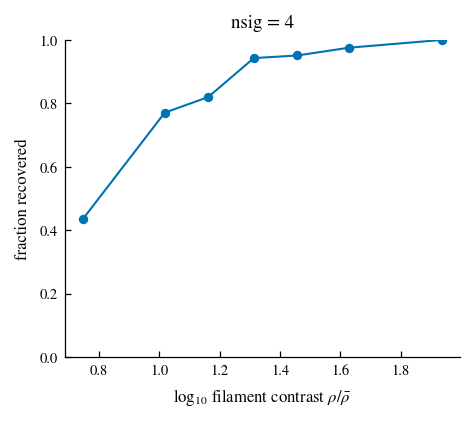

In [5]:
n_op = 4
pf = gtweb.score_per_filament(skeletons[n_op], spines, box, tol=1.5)
contrast = np.log10(np.asarray(gt["filament_target_contrast"]))
e = np.quantile(contrast, np.linspace(0, 1, 8))
i = np.clip(np.digitize(contrast, e[1:-1]), 0, 6)
fig, ax = plt.subplots(figsize=(3.4, 2.8))
ax.plot([contrast[i == b].mean() for b in range(7)], [np.mean(pf[i == b] > 0.5) for b in range(7)], "o-")
ax.set(xlabel=r"$\log_{10}$ filament contrast $\rho/\bar\rho$", ylabel="fraction recovered", ylim=(0, 1),
       title=f"nsig = {n_op}")
plt.show()

## 5. Good practice

* **Use several seeds** (`generate_mock(..., seed=s)`); one mock is one realisation.
* **Match the sampling** of your real data: subsample the particles, or use the halo catalogue as a
  tracer.
* **Read purity with care.** The diffuse component forms some faint structure away from the true
  spines; a finder that detects it is charged with false detections.
* **Nodes have four filaments.** The mock does not test how connectivity rises with node mass.
* **Velocities** are the 2LPT velocities of the initial field, not an evolved velocity field, so they
  are not suitable for testing velocity-based web classifiers on their own.